---
title: "3.3.c Riesgo por erosión de orillas"
short_title: "c. Riesgo"
subtitle: "Edificaciones en la franja de orilla activa y acceso de la ciudad al río"
description: "Exposición de edificaciones y población de Leticia a la erosión de orillas y a la pérdida de acceso al canal navegable."
keywords: [erosión, orilla, exposición, puerto, Leticia]
---

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mromerot/leticia/blob/main/book/03_analisis/33_erosion/c_riesgo.ipynb)

In [1]:
# Preparación del entorno. En Colab instala el paquete del proyecto desde GitHub (1–2 minutos);
# en una copia local usa el paquete ya instalado con `pip install -e .`.
import sys, subprocess
if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "leticia @ git+https://github.com/mromerot/leticia"], check=True)
from leticia.libro import preparar, intentar
preparar()

La erosión de orillas afecta de dos formas a Leticia: **directamente**, a las viviendas y la infraestructura
construidas sobre la orilla (barrios ribereños, malecón, muelles), y **indirectamente**, cuando la sedimentación
aleja el canal navegable y la ciudad pierde su acceso al río. La UNGRD registró eventos de erosión en Leticia en
2022 (ver [1.7](../../01_conceptos/17_perfil_riesgos.ipynb)).

In [2]:
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from leticia import aoi, espacial, exposicion, fuentes, viz
from leticia.config import parametros

pe = parametros()["erosion"]
urbana = aoi.area_urbana()
PIX_HA = (0.0003 * 111320) ** 2 * np.cos(np.radians(4.2)) / 1e4   # área de un píxel de 0,0003° en ha


def agua_anio(anio):
    ds = espacial.compuesto_landsat(anio, pe["meses_aguas_bajas"], ventana_anios=1 if anio < 2000 else 0)
    return (espacial.mndwi(ds) > pe["umbral_mndwi"]).rio.write_crs(4326), ds.attrs["escenas"]

## 1. Franja de orilla activa

In [3]:
anios = pe["anios_comparacion"]
m0, _ = agua_anio(anios[0])
m1, _ = agua_anio(anios[-1])
m0 = m0.reindex_like(m1, method="nearest")
erosion = ((~m0.astype(bool)) & m1.astype(bool)).rio.write_crs(4326)
pol_erosion = espacial.vectorizar(erosion, 15).to_crs(aoi.crs())
pol_agua = espacial.vectorizar(m1, 200).to_crs(aoi.crs())
orilla = gpd.GeoDataFrame(geometry=pol_agua.boundary, crs=aoi.crs())
franja = pe["franja_orilla_m"]
zona_orilla = orilla.buffer(franja).union_all().intersection(urbana.geometry.iloc[0])
zona_erosion = pol_erosion.buffer(franja).union_all().intersection(urbana.geometry.iloc[0])
edif = exposicion.edificaciones_urbanas()
pts = edif.representative_point()
edif["en_orilla"] = pts.within(zona_orilla)
edif["junto_a_erosion"] = pts.within(zona_erosion)
display(pd.DataFrame({
    "edificaciones": [int(edif.en_orilla.sum()), int(edif.junto_a_erosion.sum())],
    "personas": [edif.loc[edif.en_orilla, "poblacion"].sum(), edif.loc[edif.junto_a_erosion, "poblacion"].sum()],
}, index=[f"a menos de {franja} m de la orilla de aguas bajas {anios[-1]}", f"a menos de {franja} m de zonas erosionadas {anios[0]}–{anios[-1]}"]).round(0))

,edificaciones,personas
a menos de 150 m de la orilla de aguas bajas 2024,83,416.00
a menos de 150 m de zonas erosionadas 1987–2024,10,31.00


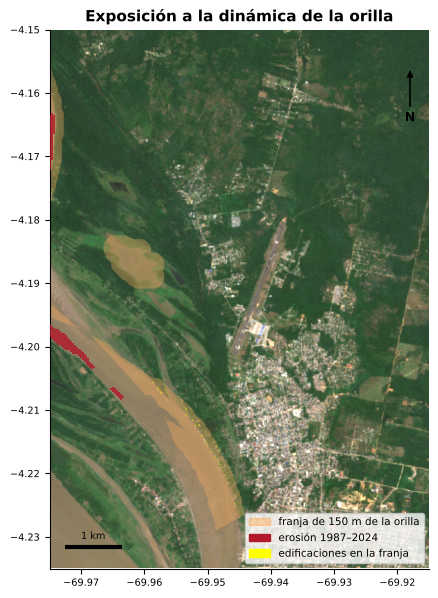

In [4]:
fig, ax = plt.subplots(figsize=(6.6, 7))
viz.fondo(ax, "bbox_urbano")
gpd.GeoSeries([zona_orilla], crs=aoi.crs()).to_crs(4326).plot(ax=ax, color="#fdae61", alpha=0.35, zorder=2)
if not pol_erosion.empty:
    pol_erosion.to_crs(4326).plot(ax=ax, color=viz.ROJO, alpha=0.8, zorder=3)
edif[edif.en_orilla].to_crs(4326).plot(ax=ax, color="yellow", linewidth=0, zorder=4)
ax.legend(handles=[Patch(color="#fdae61", alpha=0.5, label=f"franja de {franja} m de la orilla"), Patch(color=viz.ROJO, label="erosión 1987–2024"),
                   Patch(color="yellow", label="edificaciones en la franja")], loc="lower right", fontsize=7.5, frameon=True)
viz.marco(ax, "bbox_urbano", "Exposición a la dinámica de la orilla")

In [5]:
viz.pie(viz.nota_fuente("landsat", "edificaciones"))

*Fuente: USGS / NASA (Microsoft Planetary Computer) — Landsat Collection 2 Level-2 (reflectancia y temperatura de superficie); Microsoft – Global ML Building Footprints — Huellas derivadas de imágenes (2014–2024), particionadas por quadkey.*

La franja de 150 m detrás de la orilla de aguas bajas es un **criterio de tamizaje** para priorizar estudios
geotécnicos, no una zona de amenaza oficial. La socavación de barrancos (*tierras caídas*) ocurre sobre todo en la
bajada de las aguas, cuando el suelo saturado pierde el soporte del río [@pigcct2022amazonas].

## 2. Riesgo relativo por celda

,n_edif,poblacion
riesgo_erosion,,
Muy baja,708,"1,546.00"
Baja,1475,"10,011.00"
Media,3579,"29,251.00"
Alta,1038,"5,681.00"
Muy alta,8,19.00


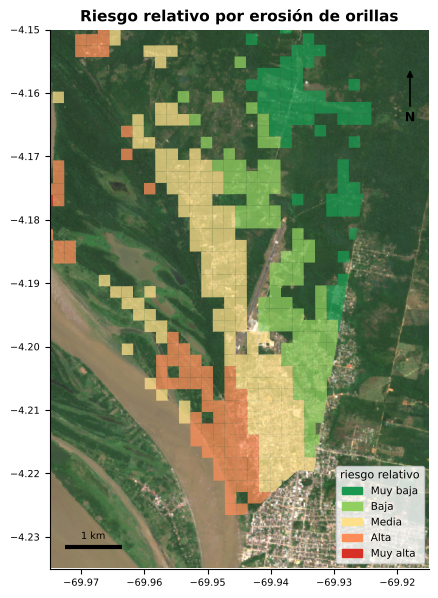

In [6]:
from leticia import riesgo
malla = exposicion.malla_exposicion()
dist_orilla = malla.geometry.centroid.distance(orilla.union_all())
dist_erosion = malla.geometry.centroid.distance(pol_erosion.union_all()) if not pol_erosion.empty else dist_orilla
amenaza_idx = 0.6 * riesgo.normalizar(dist_orilla, invertir=True) + 0.4 * riesgo.normalizar(dist_erosion, invertir=True)
malla["amenaza_erosion"] = riesgo.clasificar(amenaza_idx)
expo = riesgo.normalizar(malla["densidad_construida"]) * 0.5 + riesgo.normalizar(malla["poblacion"]) * 0.5
malla["riesgo_erosion"] = riesgo.matriz_riesgo(malla["amenaza_erosion"], riesgo.clasificar(expo.where(malla.n_edif > 0)))
con = malla[malla.n_edif > 0]
fig, ax = plt.subplots(figsize=(6.4, 7))
viz.mapa_celdas(con, "riesgo_erosion", ax=ax, categorias=riesgo.CLASES, colores=riesgo.COLORES_CLASES, etiqueta="riesgo relativo",
                titulo="Riesgo relativo por erosión de orillas")
display(con.groupby("riesgo_erosion", observed=False)[["n_edif", "poblacion"]].sum().round(0))
pd.DataFrame({"dist_orilla_m": dist_orilla, "riesgo_erosion": malla["riesgo_erosion"]}).to_csv(fuentes.ruta("riesgo_erosion_celdas.csv"))

## 3. Acceso al río: agua frente a la ciudad

In [7]:
frente = urbana.buffer(500).difference(urbana.geometry.iloc[0]).to_crs(4326)
filas = []
for anio in anios:
    m, _ = agua_anio(anio)
    v = m.astype(float).rio.clip(frente.geometry, drop=True)
    filas.append({"año": anio, "agua en la franja de 500 m (ha)": float(np.nansum(v.values)) * PIX_HA})
tab = pd.DataFrame(filas).set_index("año")
nivel = fuentes.nivel_rio()
ventanas = {a: ([a - 1, a, a + 1] if a < 2000 else [a]) for a in tab.index}
tab["nivel medio ago–nov en Leticia (m)"] = [nivel[nivel.index.year.isin(ventanas[a]) & nivel.index.month.isin(pe["meses_aguas_bajas"])].mean() / 100
                                             for a in tab.index]
display(tab.round(1))

,agua en la franja de 500 m (ha),nivel medio ago–nov en Leticia (m)
año,,
1987,365.50,8.50
2001,346.70,10.70
2013,360.10,10.30
2024,245.60,4.70


**Lectura.** La superficie de agua frente a la ciudad en aguas bajas depende del nivel del río y de la forma del
cauce. Cuando dos años tienen niveles parecidos, la diferencia de superficie refleja la sedimentación. La pérdida
de acceso al canal navegable convierte la dinámica fluvial en un riesgo para el abastecimiento de toda la ciudad
([3.2](../32_sequia/index.md)).